# 2. Scaling: finding the small parameter

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapter 1, ordinary differential equations

Asymptotic methods need a small parameter, and in a physical problem none is given:
there are only dimensional quantities, a speed of 10 m/s, a radius of 6400 km.
Whether something is small has meaning only when it is compared with something
else of the same dimensions. Finding the small parameter is therefore the first,
and often the most important, step: it means choosing scales so that the
dimensionless variables are of order one, after which the size of each term in the
equation can be read off its coefficient. This chapter works through two classic
examples. The first shows how good scaling exposes a small parameter, and how bad
scaling hides it. The second shows that a small parameter can multiply the most
important term, so that the obvious approximation loses part of the answer.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

try:
    import asymp as am
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import asymp as am

am.use_style()

## 2.1 A projectile on a round planet

A ball is thrown vertically upward from the surface of a planet of radius $R$ with
speed $v$. Its height $h(t)$ obeys Newton's law with the
inverse-square gravity,

$$ \frac{\mathrm d^2 h}{\mathrm dt^2} = -\frac{g R^2}{(R + h)^2} , \qquad
   h(0) = 0 , \quad \frac{\mathrm dh}{\mathrm dt}(0) = v , $$

with $g$ the gravity at the surface. Three parameters, $v$, $g$, $R$, can be
combined into one dimensionless group: dimensional analysis
says that $h/R$ can depend on $t$ only through $gt/v$ and on the parameters only
through

$$ \varepsilon = \frac{v^2}{gR} , $$

twice the ratio of the kinetic energy at launch to the energy needed to reach
infinity. For a ball thrown by hand on Earth, $\varepsilon \approx 10^{-5}$.

**Choosing the scales.** Which scales make the variables of order one? Everyday
experience says that a ball rises to about $v^2/g$ and stays up for about $v/g$.
With $h = (v^2/g)\,y$ and $t = (v/g)\,\tau$, the equation becomes

$$ \frac{\mathrm d^2 y}{\mathrm d\tau^2} = -\frac{1}{(1 + \varepsilon y)^2} , \qquad
   y(0) = 0 , \quad y'(0) = 1 . $$

Now every quantity is of order one except $\varepsilon$, and the equation says
plainly what to do: set $\varepsilon = 0$ to obtain the flat-Earth problem, and
correct for $\varepsilon$ in powers.

**A bad choice.** Had we scaled the height by the planet's radius, $h = R\,Y$, and
time by $R/v$, we would have found $\varepsilon\,Y'' = -1/(1 + Y)^2$, with the
small parameter multiplying the highest derivative. That looks like a singular
problem, of the kind treated in the companion book on perturbation methods, but
it is only a badly scaled one: the ball never gets near
$Y = O(1)$, and the apparent difficulty disappears with the right scales. The
right scales are those for which the solution, and its derivatives, are of order
one.

**The expansion.** Put $y = y_0 + \varepsilon y_1 + \varepsilon^2 y_2 + \dots$ and
expand $(1 + \varepsilon y)^{-2} = 1 - 2\varepsilon y + 3\varepsilon^2 y^2 - \dots$.
Collecting powers of $\varepsilon$,

$$ y_0'' = -1 , \qquad y_1'' = 2 y_0 , \qquad y_2'' = 2y_1 - 3y_0^2 , $$

each with zero initial data except $y_0'(0) = 1$. Thus $y_0 = \tau - \tau^2/2$, the
flat-Earth parabola, and

$$ y_1 = \frac{\tau^3}{3} - \frac{\tau^4}{12} . $$

Weaker gravity aloft lets the ball rise higher and stay up longer. The maximum
height can also be found exactly from energy conservation, which gives
$y_\text{max} = 1/(2 - \varepsilon)$, so that

$$ y_\text{max} = \frac12 + \frac{\varepsilon}{4} + \frac{\varepsilon^2}{8} + \dots $$

The cell checks both results against a numerical solution of the full equation.

In [2]:
def trajectory(eps, tau_end=2.6):
    sol = solve_ivp(lambda t, z: [z[1], -1.0 / (1.0 + eps * z[0])**2], (0, tau_end), [0.0, 1.0],
                    rtol=1e-12, atol=1e-14, dense_output=True)
    return sol.sol

eps_values = np.logspace(-4, -0.5, 15)
tau = np.linspace(0, 1.5, 301)                       # up to beyond the top of the flight
err_traj = {0: [], 1: []}
err_hmax = {1: [], 2: [], 3: []}
for eps in eps_values:
    y_num = trajectory(eps)(tau)[0]
    y0 = tau - tau**2 / 2
    y1 = tau**3 / 3 - tau**4 / 12
    err_traj[0].append(np.max(np.abs(y_num - y0)))
    err_traj[1].append(np.max(np.abs(y_num - y0 - eps * y1)))
    exact = 1 / (2 - eps)
    for N, approx in ((1, 0.5), (2, 0.5 + eps / 4), (3, 0.5 + eps / 4 + eps**2 / 8)):
        err_hmax[N].append(abs(exact - approx))
for k in (0, 1):
    s, p = am.loglog_slope(eps_values, err_traj[k], fit_range=(1e-4, 1e-2))
    print(f"trajectory, {k + 1} term(s): largest error for 0 < tau < 1.5 ~ {p:.3f} eps^{s:.3f}")
for N in (1, 2, 3):
    s, p = am.loglog_slope(eps_values, err_hmax[N], fit_range=(1e-4, 1e-2))
    print(f"maximum height, {N} term(s): error ~ {p:.3f} eps^{s:.3f}")
print(f"\nfor a ball thrown at 30 m/s on Earth, eps = {30**2 / (9.81 * 6.371e6):.1e}:"
      f" the round Earth raises the top by a fraction eps/2 = {30**2 / (9.81 * 6.371e6) / 2:.1e}")

trajectory, 1 term(s): largest error for 0 < tau < 1.5 ~ 0.700 eps^0.999
trajectory, 2 term(s): largest error for 0 < tau < 1.5 ~ 0.223 eps^2.001
maximum height, 1 term(s): error ~ 0.252 eps^1.001
maximum height, 2 term(s): error ~ 0.126 eps^2.001
maximum height, 3 term(s): error ~ 0.063 eps^3.001

for a ball thrown at 30 m/s on Earth, eps = 1.4e-05: the round Earth raises the top by a fraction eps/2 = 7.2e-06


Each additional term raises the order of the error by one, as it should: the
measured slopes are 1, 2 and 3. The trajectory correction is also confirmed: with
$y_1$ included the error falls from order $\varepsilon$ to order $\varepsilon^2$.

## 2.2 When the small parameter multiplies the leading term

The second example is algebraic, the quadratic equation

$$ \varepsilon x^2 + x - 1 = 0 , \qquad \varepsilon \to 0^+ . $$

Setting $\varepsilon = 0$ gives a linear equation with the single root $x = 1$.
But a quadratic has two roots, and the second has been lost. The reason is that
setting $\varepsilon = 0$ assumes the term $\varepsilon x^2$ is small, and that is
true only if $x$ is of order one. If $x$ is large, $\varepsilon x^2$ may be as
important as $x$.

**Dominant balance.** The systematic way to find all the roots is to ask which
pairs of terms can balance while the third is negligible:

* $x \sim 1$: the terms $x$ and $-1$ balance, and $\varepsilon x^2 \sim \varepsilon$
  is small. This is the root we found.
* $\varepsilon x^2 \sim x$: then $x \sim 1/\varepsilon$, both terms are of order
  $1/\varepsilon$, and the constant $-1$ is smaller. This is a consistent balance,
  and it gives the second root.
* $\varepsilon x^2 \sim 1$: then $x \sim \varepsilon^{-1/2}$, but the remaining term
  $x$ is larger than both. Inconsistent.

For the second root the right scale is therefore $x = X/\varepsilon$, which turns
the equation into $X^2 + X - \varepsilon = 0$: a **regular** problem for $X$, with
$X = -1$ at $\varepsilon = 0$. Expanding both roots,

$$ x_1 = 1 - \varepsilon + 2\varepsilon^2 - 5\varepsilon^3 + \dots , \qquad
   x_2 = -\frac{1}{\varepsilon} - 1 + \varepsilon - 2\varepsilon^2 + \dots $$

The first is a regular expansion; the second starts at order $1/\varepsilon$,
and it exists only because the problem changes character in the limit: it is a
**singular perturbation**. The same mechanism, a small parameter multiplying the
highest derivative, produces boundary layers in differential equations, the
subject of the companion book on perturbation methods. The exact roots
are known here, so the expansions can be checked directly.

In [3]:
def exact_roots(eps):
    d = np.sqrt(1 + 4 * eps)
    return 2 / (1 + d), -(1 + d) / (2 * eps)        # forms free of cancellation

eps_r = np.logspace(-4, -0.5, 15)
x1, x2 = exact_roots(eps_r)
err_root = {}
for N, coeffs in ((1, [1]), (2, [1, -1]), (3, [1, -1, 2]), (4, [1, -1, 2, -5])):
    approx1 = sum(c * eps_r**k for k, c in enumerate(coeffs))
    approx2 = -1 / eps_r + sum(c * eps_r**k for k, c in enumerate([-1, 1, -2][: N - 1]))
    err_root[(1, N)] = np.abs(x1 - approx1)
    err_root[(2, N)] = np.abs(x2 - approx2)
    s1, _ = am.loglog_slope(eps_r, err_root[(1, N)], fit_range=(1e-4, 1e-2))
    s2, _ = am.loglog_slope(eps_r, err_root[(2, N)], fit_range=(1e-4, 1e-2))
    print(f"{N} term(s): error of the regular root ~ eps^{s1:.2f};  of the singular root ~ eps^{s2:.2f}")

1 term(s): error of the regular root ~ eps^1.00;  of the singular root ~ eps^-0.00
2 term(s): error of the regular root ~ eps^2.00;  of the singular root ~ eps^1.00
3 term(s): error of the regular root ~ eps^2.99;  of the singular root ~ eps^2.00
4 term(s): error of the regular root ~ eps^4.00;  of the singular root ~ eps^2.99


For the regular root, $N$ terms leave an error of order $\varepsilon^N$. For the
singular root, $N$ terms starting at $-1/\varepsilon$ leave an error of order
$\varepsilon^{N-1}$: the one-term approximation $-1/\varepsilon$ is wrong by an
amount of order one, which is nonetheless small *relative to the root itself*.
Whether an error is small must always be judged against the quantity being
approximated.

## 2.3 A recipe

The two examples suggest the procedure that the rest of the book follows.

1. Write the problem in dimensionless form, with scales chosen so that the
   unknowns and their derivatives are of order one. Dimensional analysis tells how
   many dimensionless groups there are; physical estimates suggest the scales.
2. Read the small parameter off the coefficients. If a small parameter multiplies
   the highest derivative or the highest power, expect part of the solution to be
   lost when it is set to zero, and look for other scalings by dominant balance.
3. Expand, solve order by order, and check the result against an accurate
   numerical solution: the error should fall with the slope the expansion
   predicts.

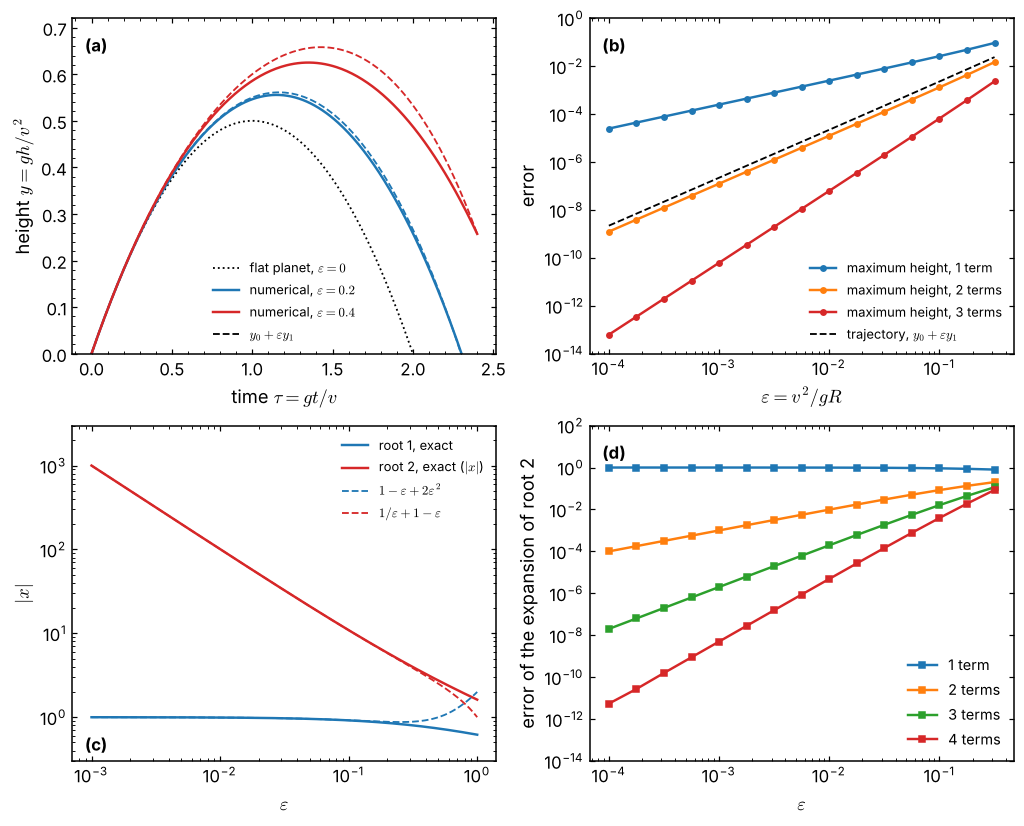

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))

ax = axes[0, 0]
tt = np.linspace(0, 2.4, 300)
for eps, c in ((0.0, "k"), (0.2, "C0"), (0.4, "C3")):
    if eps == 0:
        ax.plot(tt, tt - tt**2 / 2, "k:", lw=1.2, label=r"flat planet, $\varepsilon = 0$")
        continue
    ax.plot(tt, trajectory(eps)(tt)[0], color=c, label=rf"numerical, $\varepsilon = {eps}$")
    ax.plot(tt, tt - tt**2 / 2 + eps * (tt**3 / 3 - tt**4 / 12), "--", color=c, lw=1.2)
ax.plot([], [], "k--", lw=1.2, label=r"$y_0 + \varepsilon y_1$")
ax.set_xlabel(r"time $\tau = gt/v$"); ax.set_ylabel(r"height $y = gh/v^2$")
ax.set_ylim(0, 0.72); ax.legend(loc="lower center", fontsize=8.5); am.panel_label(ax, "(a)")

ax = axes[0, 1]
for N, c in zip((1, 2, 3), ("C0", "C1", "C3")):
    ax.loglog(eps_values, err_hmax[N], "o-", ms=3.5, color=c, label=f"maximum height, {N} term" + ("s" if N > 1 else ""))
ax.loglog(eps_values, err_traj[1], "k--", lw=1.2, label=r"trajectory, $y_0 + \varepsilon y_1$")
ax.set_xlabel(r"$\varepsilon = v^2/gR$"); ax.set_ylabel("error")
ax.set_ylim(1e-14, 1); ax.legend(loc="lower right", fontsize=8.5); am.panel_label(ax, "(b)")

ax = axes[1, 0]
ee = np.logspace(-3, 0, 200)
r1, r2 = exact_roots(ee)
ax.loglog(ee, r1, "C0", label="root 1, exact")
ax.loglog(ee, np.abs(r2), "C3", label=r"root 2, exact ($|x|$)")
ax.loglog(ee, 1 - ee + 2 * ee**2, "C0--", lw=1.2, label=r"$1 - \varepsilon + 2\varepsilon^2$")
ax.loglog(ee, 1 / ee + 1 - ee, "C3--", lw=1.2, label=r"$1/\varepsilon + 1 - \varepsilon$")
ax.set_xlabel(r"$\varepsilon$"); ax.set_ylabel(r"$|x|$")
ax.set_ylim(0.3, 3e3); ax.legend(loc="upper right", fontsize=8.5); am.panel_label(ax, "(c)", y=0.08)

ax = axes[1, 1]
for N, c in zip((1, 2, 3, 4), ("C0", "C1", "C2", "C3")):
    ax.loglog(eps_r, err_root[(2, N)], "s-", ms=3.5, color=c, label=f"{N} term" + ("s" if N > 1 else ""))
ax.set_xlabel(r"$\varepsilon$"); ax.set_ylabel("error of the expansion of root 2")
ax.set_ylim(1e-14, 1e2); ax.legend(loc="lower right"); am.panel_label(ax, "(d)")
plt.show()

**(a)** Trajectories on a round planet (solid: numerical solution; dashed: two-term
expansion) and on a flat one (dotted). **(b)** Errors of the expansions of the
maximum height and of the trajectory against $\varepsilon$. **(c)** The two roots of
$\varepsilon x^2 + x - 1 = 0$ with their expansions. **(d)** Error of the
expansion of the singular root, starting from $-1/\varepsilon$: $N$ terms leave an
error of order $\varepsilon^{N-1}$.

## Summary

* Smallness is relative: a parameter is small only after the problem is made
  dimensionless with scales that make the unknowns of order one.
* Dimensional analysis counts the independent groups; physical estimates choose
  the scales. A bad choice of scales can make a regular problem look singular.
* If setting the parameter to zero lowers the order of the equation, part of the
  solution is lost. Dominant balance finds the scalings that recover it.
* Every expansion is checked by the slope of its error against an accurate
  solution.

## Suggested references

* G. I. Barenblatt, *Scaling, Self-Similarity, and Intermediate Asymptotics*
  (Cambridge University Press, 1996).
* C. M. Bender and S. A. Orszag, *Advanced Mathematical Methods for Scientists
  and Engineers* (McGraw-Hill, 1978; Springer, 1999).
* E. J. Hinch, *Perturbation Methods* (Cambridge University Press, 1991).
* M. H. Holmes, *Introduction to Perturbation Methods*, 2nd ed. (Springer, 2013).
* C. C. Lin and L. A. Segel, *Mathematics Applied to Deterministic Problems in the
  Natural Sciences* (Macmillan, 1974; SIAM, 1988).

## Exercises

1. Find $y_2$ for the projectile, and check that it reproduces the
   $\varepsilon^2/8$ term of the maximum height.
2. Show that the time of flight is $2 + \tfrac43\varepsilon + O(\varepsilon^2)$ and
   confirm the slope of its error numerically.
3. Find all roots of $\varepsilon x^3 + x^2 - 1 = 0$ for small $\varepsilon$ by
   dominant balance, to two terms each.
4. A sphere of radius $a$ falls through a fluid of viscosity $\mu$ and density
   $\rho$. Form the dimensionless groups and say which small parameter justifies
   Stokes' law.

---

**Previous:** [1. What an asymptotic expansion is](01_what_is_an_asymptotic_expansion.ipynb) &nbsp;·&nbsp; **Next:** [3. Order symbols, gauge functions and uniqueness](03_order_symbols_and_gauge_functions.ipynb)